# Regresión logística con umbral por bisección y evaluación por Monte Carlo

**Proyecto final — Simulación Digital y Análisis Numérico**

---

## Objetivo general

Desarrollar un clasificador de tumores de mama que detecte la mayor cantidad posible de casos malignos, con un umbral de decisión justificado y una estimación confiable de su desempeño.

## Objetivos específicos

- **OE1.** Entrenar un modelo de regresión logística y evaluar su *accuracy* y su sensibilidad en un conjunto de prueba.
- **OE2.** Usar el método de bisección para encontrar el umbral de decisión más alto que garantice una sensibilidad mínima de $0.95$.
- **OE3.** Estimar con simulación Monte Carlo la variabilidad del *accuracy* y la probabilidad de cumplir la sensibilidad mínima, repitiendo el experimento 100 veces con particiones train/test distintas.

## ¿Qué es un tumor maligno y por qué detectarlo es lo importante?

Un **tumor benigno** crece de forma localizada y ordenada: puede ser molesto, pero no invade los tejidos vecinos ni se disemina a otras partes del cuerpo. Un **tumor maligno** (cáncer de mama) crece sin control, invade los tejidos cercanos y puede extenderse a otros órganos (metástasis); por eso amenaza la vida y su tratamiento es mucho más agresivo.

Al usar un modelo como apoyo al diagnóstico, hay dos formas de equivocarse:

- **Falso negativo:** decir "benigno" a un tumor que en realidad es maligno → el paciente podría no recibir tratamiento a tiempo. Es el error más costoso.
- **Falso positivo:** decir "maligno" a un tumor benigno → el paciente pasa sustos y se hacen exámenes de más, pero el error se corrige sin dañar la salud.

Con esa prioridad, el proyecto se concentra en la clase maligna: el clasificador se ajusta y se evalúa para **detectar la mayor cantidad posible de casos malignos**, medido por la **sensibilidad**. Esa misma prioridad justifica buscar un **umbral de decisión** especial (OE2) en lugar de aceptar el umbral por defecto de $0.5$, y estimar con **Monte Carlo** qué tan confiable es la garantía de sensibilidad (OE3).

## 1. Datos

En este bloque cargamos el conjunto de datos y dejamos claro quién es la clase positiva.

- **Qué se hace:** cargar el dataset de cáncer de mama incluido en scikit-learn (`load_breast_cancer`), construir la matriz de características $X$ y el vector de etiquetas $y$, y mostrar la forma del dataset, el balance de clases y las primeras filas.
- **Por qué se eligió:** es un dataset **real de diagnóstico** (mediciones calculadas a partir de imágenes de células obtenidas por aspiración con aguja fina de tumores de mama), incluido en scikit-learn, Se descartó usar un dataset sintético (no representa la dificultad real del problema) o uno externo con descarga (depende de internet y puede fallar).
- **Para qué:** estos datos son la materia prima del modelo; todo lo demás (partición, entrenamiento, umbral por bisección, Monte Carlo) se construye encima de ellos.

**Definición clave de las etiquetas.** En el dataset original, `target = 0` es **maligno** y `target = 1` es **benigno** (es la convención del dataset, no del problema). Aquí redefinimos

$$y = 1 - \text{target}$$

para que **la clase positiva ($y=1$) sea el tumor maligno**. ¿Por qué? Porque la métrica central del proyecto es la **sensibilidad**:

$$\text{Sensibilidad} = \frac{\text{verdaderos positivos}}{\text{verdaderos positivos} + \text{falsos negativos}},$$

que mide la fracción de **casos malignos** que el modelo logra detectar. Si la clase maligna no fuera la positiva ($y=1$), la sensibilidad estaría midiendo erróneamente los benignos y no respondería al objetivo del proyecto.

**Resultado esperado:** $569$ muestras con $30$ características numéricas, con aproximadamente un $37\%$ de tumores malignos y un $63\%$ de benignos (clases desbalanceadas, pero no de forma extrema). En las primeras filas se espera ver columnas numéricas con escalas muy distintas entre sí, lo que más adelante justificará estandarizar los datos.

In [51]:
# LIBRERÍAS BASE DEL PROYECTO
# numpy: operaciones numéricas; pandas: manejo de datos en tabla;
# sklearn: dataset de cáncer de mama y (más adelante) el modelo.
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer

# Cargamos el dataset incluido en scikit-learn (no requiere descarga).
datos = load_breast_cancer()

# X: matriz de características (cada fila es un tumor, cada columna una medición).
X = pd.DataFrame(datos.data, columns=datos.feature_names)

# REETIQUETADO: en el dataset original target 0 = MALIGNO y target 1 = BENIGNO.
# Definimos y = 1 - target para que la clase positiva (y = 1) sea el MALIGNO.
# Razón: la sensibilidad mide cuántos malignos detecta el modelo, y para
# medirla correctamente el maligno debe ser la clase positiva.
y = pd.Series(1 - datos.target, name="maligno")

print("Forma del dataset (muestras, características):", X.shape)
print("Clases originales del dataset (target_names):", list(datos.target_names))

# Balance de clases: cuántas muestras hay de cada clase y en qué porcentaje.
conteo = y.map({1: "maligno (y=1)", 0: "benigno (y=0)"}).value_counts()
resumen_clases = pd.DataFrame({
    "muestras": conteo,
    "porcentaje (%)": (conteo / len(y) * 100).round(2)
})
resumen_clases

Forma del dataset (muestras, características): (569, 30)
Clases originales del dataset (target_names): [np.str_('malignant'), np.str_('benign')]


,muestras,porcentaje (%)
maligno,,
benigno (y=0),357,62.74
maligno (y=1),212,37.26


In [52]:
# Primeras 5 filas del dataset, transpuestas para poder ver las 30
# características de cada tumor. Agregamos la clase como primera fila
# para ver junto las mediciones y su diagnóstico.
primeras = X.head(5).copy()
primeras.insert(0, "clase", y.head(5).map({1: "maligno", 0: "benigno"}).values)
primeras.T

,0,1,2,3,4
clase,maligno,maligno,maligno,maligno,maligno
mean radius,17.99,20.57,19.69,11.42,20.29
mean texture,10.38,17.77,21.25,20.38,14.34
mean perimeter,122.8,132.9,130.0,77.58,135.1
mean area,1001.0,1326.0,1203.0,386.1,1297.0
mean smoothness,0.1184,0.08474,0.1096,0.1425,0.1003
mean compactness,0.2776,0.07864,0.1599,0.2839,0.1328
mean concavity,0.3001,0.0869,0.1974,0.2414,0.198
mean concave points,0.1471,0.07017,0.1279,0.1052,0.1043
mean symmetry,0.2419,0.1812,0.2069,0.2597,0.1809


**Interpretación de los resultados.**

- Hay **569 tumores** y **30 características numéricas** (radio, textura, perímetro, área, etc., con su media, error estándar y valor "worst").
- Con $y = 1 - \text{target}$ queda: **212 malignos ($\approx 37.26\%$)** y **357 benignos ($\approx 62.74\%$)**. El problema es binario con un desbalance moderado.
- El desbalance tiene una consecuencia importante: el *accuracy* por sí solo puede engañar. Un modelo tonto que siempre diga "benigno" acertaría $\approx 62.7\%$ de las veces **sin detectar ni un solo maligno**. Por eso el proyecto mira principalmente la **sensibilidad**.
- Las escalas de las columnas van desde centésimas hasta miles. Sin estandarizar, las características de escala grande dominarían el ajuste de la regresión logística; en la sección 2 se corrige esto.

## 2. Partición y estandarización

Antes de entrenar hay que hacer dos preparaciones: separar datos de prueba y poner las 30 características en una escala común.

### 2.1 Partición train/test

- **Qué se hace:** dividir los 569 tumores en **entrenamiento** (train, 80 %) y **prueba** (test, 20 %), con partición **estratificada** y semilla fija (`SEMILLA = 42`), y verificar que ambos conjuntos conservan el balance de clases.
- **Por qué se eligió:** el test simula tumores "nuevos": si midiéramos el modelo con datos que ya vio, la evaluación sería optimista e irreal. La partición es **estratificada** porque con pocos datos una división puramente al azar podría, por mala suerte, dejar una clase mal representada en alguno de los dos conjuntos y distorsionar la evaluación; la estratificación fuerza la proporción real 37/63 en ambos. La **semilla fija** hace que cualquier persona que ejecute el notebook obtenga exactamente los mismos resultados (se descarta una semilla aleatoria: rompe la reproducibilidad). Se descartó un test más pequeño (por ejemplo 10 %) porque dejaría muy pocos malignos en test (≈ 21) y la sensibilidad se estimaría con mucho ruido.
- **Para qué:** el train se usa para ajustar el modelo; el test queda reservado para la evaluación final (secciones 3 y 4).
- **Resultado esperado:** 455 tumores en train y 114 en test, con el ≈ 37.26 % de malignos en los dos.

In [53]:
from sklearn.model_selection import train_test_split

# SEMILLA FIJA: se usa en TODO elemento aleatorio del proyecto
# (particiones, validación cruzada de la sección 4 y Monte Carlo de la 5).
SEMILLA = 42

# Partición estratificada: separamos 20 % para test pero conservando
# la proporción de clases (stratify=y).
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA
)

print("Tamaño de train:", X_train.shape[0], "tumores")
print("Tamaño de test :", X_test.shape[0], "tumores")

# Verificación de la estratificación: cuántos y qué % de cada clase
# quedaron en cada conjunto.
balance_particiones = pd.DataFrame({
    "train: n": y_train.map({1: "maligno (y=1)", 0: "benigno (y=0)"}).value_counts(),
    "train: %": (y_train.map({1: "maligno (y=1)", 0: "benigno (y=0)"}).value_counts(normalize=True) * 100).round(2),
    "test: n": y_test.map({1: "maligno (y=1)", 0: "benigno (y=0)"}).value_counts(),
    "test: %": (y_test.map({1: "maligno (y=1)", 0: "benigno (y=0)"}).value_counts(normalize=True) * 100).round(2),
})
balance_particiones

Tamaño de train: 455 tumores
Tamaño de test : 114 tumores


,train: n,train: %,test: n,test: %
maligno,,,,
benigno (y=0),285,62.64,72,63.16
maligno (y=1),170,37.36,42,36.84


### 2.2 Estandarización

- **Qué se hace:** estandarizar cada característica con `StandardScaler`: a cada columna se le resta su media y se divide por su desviación estándar. La media y la desviación se calculan **solo con train**, y esa misma transformación se aplica después a test.
- **Por qué se eligió:** en la sección 1 vimos que las escalas van desde centésimas hasta miles. La regresión logística de sklearn penaliza el tamaño de los coeficientes (regularización L2): sin estandarizar, esa penalización castigaría de forma desigual a las características y el entrenamiento converge peor. Se descartó `MinMaxScaler` (aplasta todo a $[0,1]$ pero es muy sensible a valores extremos) y no escalar (deja el desbalance de escalas intacto).
- **Detalle clave — evitar la fuga de datos:** si calculáramos la media y la desviación con TODO el dataset, información de los tumores del test (que deberían ser "nuevos") se colaría en la preparación. Por eso el escalador se ajusta **solo con train** y el test se transforma con las constantes aprendidas en train. Es la misma lógica de "guardar el test bajo llave".
- **Para qué:** el modelo de la sección 3 se entrena con datos estandarizados, para que todas las características compitan en igualdad de condiciones.
- **Resultado esperado:** en train estandarizado cada columna queda con media ≈ 0 y desviación ≈ 1.

In [54]:
from sklearn.preprocessing import StandardScaler

# Se ajusta el estandarizador SOLO con train: de ahí aprende una media
# y una desviación por cada una de las 30 características.
scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)  # aprende de train y transforma train
X_test_esc = scaler.transform(X_test)        # transforma test con lo aprendido en train

# Comparación: escala de las características antes y después (primeras 8).
# Se usa la desviación poblacional (ddof=0), la misma que usa el escalador.
antes_despues = pd.DataFrame({
    "media antes": X_train.values.mean(axis=0),
    "desv. antes": X_train.values.std(axis=0),
    "media después": X_train_esc.mean(axis=0),
    "desv. después": X_train_esc.std(axis=0),
}, index=X.columns).round(4)
antes_despues.head(8)

,media antes,desv. antes,media después,desv. después
mean radius,14.1661,3.5751,-0.0,1.0
mean texture,19.4177,4.2859,0.0,1.0
mean perimeter,92.2159,24.6899,0.0,1.0
mean area,659.5782,360.0224,-0.0,1.0
mean smoothness,0.0960,0.0143,0.0,1.0
mean compactness,0.1038,0.0539,-0.0,1.0
mean concavity,0.0892,0.0816,-0.0,1.0
mean concave points,0.0490,0.0396,0.0,1.0


## 3. Modelo: regresión logística (OE1)

Este bloque cumple el OE1: entrenar el clasificador y evaluarlo con el umbral por defecto.

### 3.1 ¿Qué es la regresión logística y por qué se elige?

La **regresión logística** es un modelo de clasificación binaria que estima la **probabilidad** de que un tumor sea maligno. En vez de ajustar una recta (que puede tomar valores fuera de $[0,1]$), toma una combinación lineal de las 30 características y la pasa por la **función sigmoide**, que siempre devuelve un número entre 0 y 1:

$$P(y=1 \mid \mathbf{x}) = \frac{1}{1 + e^{-(b + w_1 x_1 + w_2 x_2 + \dots + w_{30} x_{30})}}$$

El modelo aprende los coeficientes $b, w_1, \dots, w_{30}$ a partir de los datos de train. Cuanto más cerca de 1 sale la probabilidad, más segura es la predicción de "maligno".

- **Por qué se eligió:** produce directamente **probabilidades**, y este proyecto las necesita: el OE2 va a mover el umbral de decisión $t$ (seclasifica como maligno cuando $P \geq t$), lo cual solo tiene sentido si el modelo devuelve una probabilidad. Además es **interpretable** (cada coeficiente refleja el efecto de una característica) y es el modelo estándar para clasificación binaria. **Alternativas descartadas:** SVM (separa clases pero no entrega probabilidades de forma natural), bosque aleatorio (es una caja negra y sus "probabilidades" son proporciones de votos, menos confiables como tales) y regresión lineal (predice valores fuera de $[0,1]$, que no son probabilidades).
- **Qué se hace ahora:** entrenar `LogisticRegression` con train estandarizado, calcular en test las probabilidades $P(\text{maligno})$ y clasificar con el **umbral por defecto 0.5**.
- **Para qué:** este modelo es el corazón del proyecto; sus probabilidades alimentan la búsqueda del umbral por bisección (sección 4) y la simulación Monte Carlo (sección 5).
- **Resultado esperado:** el modelo debería aprender bien el patrón (accuracy alto, ≈ 0.95–0.98). El punto de interés es la **sensibilidad**: ver si con el umbral 0.5 se detectan al menos el 95 % de los malignos.

In [55]:
from sklearn.linear_model import LogisticRegression

# Modelo de regresión logística.
# max_iter=1000: margen de iteraciones para que el optimizador converja
# sin warnings (con datos estandarizados converge con holgura).
modelo = LogisticRegression(max_iter=1000, random_state=SEMILLA)

# Se entrena SOLO con el train estandarizado.
modelo.fit(X_train_esc, y_train)

# Probabilidades en test (TUMORES QUE EL MODELO NO CONOCÍA).
# predict_proba devuelve dos columnas: P(y=0) y P(y=1); la columna 1 es
# P(maligno), la que se usa en todo el proyecto.
p_test = modelo.predict_proba(X_test_esc)[:, 1]

# Clasificación con el UMBRAL POR DEFECTO:
# si P(maligno) >= 0.5 se declara maligno; si no, benigno.
UMBRAL_DEFECTO = 0.5
y_pred_test = (p_test >= UMBRAL_DEFECTO).astype(int)

print("Primeras 8 probabilidades de test, P(maligno):")
print(np.round(p_test[:8], 4))
print("Primeras 8 clasificaciones con umbral 0.5:", y_pred_test[:8])

Primeras 8 probabilidades de test, P(maligno):
[4.000e-04 1.000e+00 4.260e-02 5.762e-01 5.092e-01 6.000e-04 7.615e-01
 1.000e-03]
Primeras 8 clasificaciones con umbral 0.5: [0 1 0 1 1 0 1 0]


### 3.2 Evaluación con el umbral 0.5

- **Qué se hace:** medir en test el **accuracy**, la **matriz de confusión** y la **sensibilidad** con el umbral 0.5.
- **Por qué se hace así:** el accuracy lo resume todo en un número y puede esconder el error que importa. La matriz de confusión separa los 4 casos posibles y deja ver los **falsos negativos**; la sensibilidad se calcula a mano, $S = VP/(VP+FN)$, para que se vea de dónde sale en lugar de tratarla como una caja negra de sklearn.
- **Para qué:** esta es la línea base del proyecto: si con 0.5 la sensibilidad no llega a 0.95, queda demostrado que el umbral por defecto **no** garantiza la meta y se justifica buscar el umbral por bisección (OE2).
- **Resultado esperado:** con 114 tumores de test (72 benignos y 42 malignos), un clasificador razonable acierta la mayoría; lo delicado es cuántos malignos se le escapan (FN).

In [56]:
from sklearn.metrics import accuracy_score, confusion_matrix

# Accuracy: fracción de tumores clasificados correctamente.
acc_defecto = accuracy_score(y_test, y_pred_test)

# Matriz de confusión: filas = clase real, columnas = clase predicha.
mc = confusion_matrix(y_test, y_pred_test, labels=[0, 1])
matriz_confusion = pd.DataFrame(
    mc,
    index=["real: benigno (0)", "real: maligno (1)"],
    columns=["predicho: benigno (0)", "predicho: maligno (1)"],
)

# Los 4 casos: VN = benigno bien clasificado, FP = benigno alarmado,
# FN = MALIGNO QUE SE ESCAPA, VP = maligno detectado.
VN, FP, FN, VP = mc.ravel()

# Sensibilidad a mano: de todos los malignos reales,
# ¿qué fracción logró detectar el modelo?
sens_defecto = VP / (VP + FN)

print(f"Accuracy en test (umbral 0.5):     {acc_defecto:.4f}  ({VN + VP}/{len(y_test)} aciertos)")
print(f"Sensibilidad en test (umbral 0.5): {sens_defecto:.4f}  ({VP}/{VP + FN} malignos detectados)")
matriz_confusion

Accuracy en test (umbral 0.5):     0.9649  (110/114 aciertos)
Sensibilidad en test (umbral 0.5): 0.9286  (39/42 malignos detectados)


,predicho: benigno (0),predicho: maligno (1)
real: benigno (0),71,1
real: maligno (1),3,39


### 3.3 Interpretación: el falso negativo es el error que importa

**Qué muestran los números** (con la semilla fija del proyecto):

- **Accuracy ≈ 0.9649**: el modelo acierta 110 de los 114 tumores de test. Aparentemente muy bien.
- **Sensibilidad = 39/42 ≈ 0.9286**: el modelo solo detecta 39 de los 42 malignos. Los **3 falsos negativos** son tumores malignos a los que el modelo dijo "benigno".
- El único falso positivo (benigno alarmado) es molesto pero inofensivo: se aclara con estudios adicionales.

**Por qué el falso negativo es el error más costoso:** un falso negativo es un paciente con cáncer que se va a casa sin tratamiento, con el tumor siguiendo su curso. El costo de un falso positivo son exámenes de más y un susto; el costo de un falso negativo puede ser la vida. Por eso la métrica reina del proyecto es la **sensibilidad**, no el accuracy.

**Por qué esto motiva el OE2:** el umbral 0.5 deja la sensibilidad en ≈ 0.93, **por debajo de la meta de 0.95**. La sensibilidad se puede aumentar **bajando el umbral**: con $t < 0.5$ el modelo declara "maligno" con más facilidad y se le escapan menos casos. Pero tampoco conviene bajarlo sin control (cada reducción de $t$ fabrica más falsos positivos y el modelo deja de ser útil). El problema es entonces **encontrar el nivel justo**: el umbral **más alto** que todavía garantiza sensibilidad ≥ 0.95, para perder la menor especificidad posible. Esa búsqueda es un problema de raíz de una función, y se resuelve con **bisección** en la sección 4.

## 4. Bisección para el umbral (OE2)

La sección 3 terminó con una pregunta abierta: ¿cuál es el umbral $t$ "justo" para que la sensibilidad llegue al menos a 0.95 sin sacrificar de más la especificidad? Este bloque la resuelve con **bisección**, cumpliendo el OE2.

### Planteamiento: las funciones S(t) y g(t)

Para un umbral $t$, se clasifica como maligno todo tumor con $P(\text{maligno}) \geq t$, y se mide la sensibilidad resultante:

$$S(t) = \frac{VP(t)}{VP(t) + FN(t)}, \qquad g(t) = S(t) - 0.95$$

Buscamos el **umbral más alto** que todavía garantiza $S(t) \geq 0.95$, es decir, el punto donde $g(t)$ pasa de positivo (o cero) a negativo. Tres observaciones hacen viable la búsqueda:

- Al subir $t$, clasificar como maligno es más difícil, así que **S(t) nunca crece** (es monótona no creciente).
- $S(0) = 1$ (con $t=0$ todo se predice maligno) $\Rightarrow g(0) = +0.05$.
- $S(1) \approx 0$ (con $t=1$ casi nada se predice maligno) $\Rightarrow g(1) < 0$.

Con eso, $g$ cambia de signo en $[0,1]$: el corte existe y está en ese intervalo.

**Por qué bisección y no otro método numérico:** $S(t)$ es una **función escalonada**: solo cambia cuando $t$ cruza una de las 455 probabilidades del train; entre escalones es constante, o sea que su derivada es 0 casi en todas partes. **Newton-Raphson** necesita la derivada (y que no se anule): con derivada 0 en casi todo el dominio se queda clavado o divaga; ni siquiera aplica bien a funciones discontinuas. La **bisección** solo pide un cambio de signo: con evaluar $g$ en el punto medio se sabe en qué mitad seguir, el intervalo se reduce a la mitad en cada paso y converge garantizadamente. También se descartó `scipy.optimize.brentq`: encontraría lo mismo, pero la idea del proyecto es implementar el método numérico a mano y verlo trabajar, no usarlo como caja negra.

- **Qué se hace en el bloque:** definir $S$ y $g$ con numpy, obtener en el train probabilidades de **validación cruzada**, buscar la raíz de $g$ con bisección propia (intervalo $[0,1]$, tolerancia $10^{-6}$, máximo 100 iteraciones) mostrando la tabla de iteraciones, y verificar el resultado contra una búsqueda exhaustiva.
- **Para qué:** el umbral $t^*$ que salga será la **regla de decisión final** del clasificador; su confiabilidad se examina con Monte Carlo en la sección 5.
- **Resultado esperado:** como en el train $S(0.5) \approx 0.947 < 0.95$, el umbral debería quedar **ligeramente por debajo de 0.5**; el intervalo debería encerrar el corte en unas 20 iteraciones ($\log_2(1/10^{-6}) \approx 20$).

### 4.1 Las probabilidades para fijar el umbral: validación cruzada sobre train

Una regla que no se puede saltar: **el umbral se elige usando solo el train, jamás el test.** Si usáramos el test para elegir $t$ y luego evaluáramos en ese mismo test, estaríamos "entrenando" parte de la decisión con los datos del examen: la evaluación saldría inflada y optimista. El test solo se usa una vez, al final.

¿De dónde salen entonces las probabilidades? De la **validación cruzada** (`cross_val_predict`): el train se divide en 5 partes (folds); cada tumor del train recibe su $P(\text{maligno})$ de un modelo entrenado con las otras 4 partes, es decir, **de un modelo que no lo vio**. Así, la $S(t)$ calculada sobre estas probabilidades imita honestamente cómo se portará la regla con tumores nuevos.

- **Qué se hace:** construir un **Pipeline** (escalador + regresión logística) y calcular `cross_val_predict(..., cv=5, method="predict_proba")` sobre el train; también se define la función $S(t)$.
- **Por qué el Pipeline:** para que, dentro de la validación cruzada, cada modelo se estandarice solo con sus 4 folds de entrenamiento. Sin pipeline, cada fold de validación se estandarizaría con información de sí misma: la misma fuga de datos de la sección 2, pero en pequeño.
- **Para qué:** estas 455 probabilidades "honestas" son la base sobre la que se define $g(t)$ y se hace la bisección.
- **Resultado esperado:** $S(0) = 1$, $S(1) \approx 0$ (puede que 1 o 2 tumores tengan probabilidad exactamente 1) y, sobre todo, $S(0.5) < 0.95$: la confirmación de que hay que bajar el umbral.

In [57]:
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import Pipeline

# S(t): sensibilidad que resulta al clasificar como maligno todo tumor
# con probabilidad >= t, sobre un conjunto dado de probabilidades.
def sensibilidad_umbral(t, probabilidades, etiquetas):
    predicho_maligno = probabilidades >= t
    es_maligno = etiquetas == 1
    VP = np.sum(predicho_maligno & es_maligno)
    FN = np.sum(~predicho_maligno & es_maligno)
    return VP / (VP + FN)

# Pipeline: estandariza y entrena JUNTOS, de modo que dentro de la
# validación cruzada cada modelo se ajusta solo con sus folds de entrenamiento.
tuberia = Pipeline([
    ("escalar", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000, random_state=SEMILLA)),
])

# Probabilidades de validación cruzada sobre el TRAIN: cada tumor de train
# recibe P(maligno) de un modelo entrenado con los otros 4 folds (no lo vio).
p_cv = cross_val_predict(tuberia, X_train, y_train, cv=5,
                         method="predict_proba")[:, 1]
y_train_arr = np.asarray(y_train)

print("S(0.0) =", round(sensibilidad_umbral(0.0, p_cv, y_train_arr), 4), " (todo se predice maligno)")
print("S(0.5) =", round(sensibilidad_umbral(0.5, p_cv, y_train_arr), 4))
print("S(1.0) =", round(sensibilidad_umbral(1.0, p_cv, y_train_arr), 4))

S(0.0) = 1.0  (todo se predice maligno)
S(0.5) = 0.9471
S(1.0) = 0.0118


### 4.2 Búsqueda de la raíz: bisección hecha a mano

- **Qué se hace:** implementar la bisección con numpy puro (sin `scipy.optimize`). Se parte de $[a, b] = [0, 1]$; en cada iteración se evalúa $g$ en el punto medio $c = (a+b)/2$: si $g(c) \geq 0$ la meta aún se cumple y el umbral puede seguir subiendo ($a \leftarrow c$); si $g(c) < 0$ la meta se incumple y hay que bajar ($b \leftarrow c$). Se repite hasta que el ancho $(b - a)$ baje de la tolerancia ($10^{-6}$) o se completen 100 iteraciones.
- **Por qué funciona:** el invariante se mantiene siempre: $g(a) \geq 0$ y $g(b) < 0$, de modo que el cambio de signo queda encerrado en $[a, b]$ en todas las iteraciones (aquí la monotonía de $S$ es esencial).
- **Para qué:** el resultado es $t^*$, el umbral más alto que garantiza sensibilidad $\geq 0.95$ sobre las probabilidades de validación cruzada del train.
- **Resultado esperado:** una tabla donde el ancho va $1, 0.5, 0.25, \dots$ partiéndose a la mitad, hasta quedar por debajo de $10^{-6}$ (unas 20 iteraciones). La columna $g(c)$ es el "error con signo": cuánto le falta (o le sobra) a la sensibilidad respecto a la meta.

In [58]:
# MÉTODO DE BISECCIÓN, IMPLEMENTADO A MANO.
# Invariante en toda iteración: g(a) >= 0 y g(b) < 0,
# o sea, el cambio de signo queda encerrado en [a, b].
# Devuelve el umbral más alto con S(t) >= meta y la tabla de iteraciones.
def biseccion_umbral(probabilidades, etiquetas, meta=0.95,
                     a=0.0, b=1.0, tolerancia=1e-6, max_iteraciones=100):
    historial = []
    for i in range(max_iteraciones):
        c = (a + b) / 2
        gc = sensibilidad_umbral(c, probabilidades, etiquetas) - meta
        historial.append({
            "iteración": i + 1,
            "a": a, "b": b, "c": c,
            "g(c)": gc,
            "ancho (b-a)": b - a,
        })
        if gc >= 0.0:
            a = c
        else:
            b = c
        if (b - a) < tolerancia:
            break
    # Cualquier punto del intervalo final es válido dentro de la tolerancia;
    # se devuelve el punto medio (el estándar en bisección).
    umbral = (a + b) / 2
    return umbral, pd.DataFrame(historial)

umbral_biseccion, tabla_biseccion = biseccion_umbral(p_cv, y_train_arr)

s_en_umbral = sensibilidad_umbral(umbral_biseccion, p_cv, y_train_arr)
print(f"Umbral encontrado:            {umbral_biseccion:.7f}")
print(f"Iteraciones:                 {len(tabla_biseccion)}")
print(f"S en entrenamiento (CV):     {s_en_umbral:.4f}  (meta: 0.95)")
print()
tabla_biseccion.round(7)

Umbral encontrado:            0.4819331
Iteraciones:                 20
S en entrenamiento (CV):     0.9529  (meta: 0.95)



,iteración,a,b,c,g(c),ancho (b-a)
0,1,0.000000,1.000000,0.500000,-0.002941,1.000000
1,2,0.000000,0.500000,0.250000,0.020588,0.500000
2,3,0.250000,0.500000,0.375000,0.014706,0.250000
3,4,0.375000,0.500000,0.437500,0.008823,0.125000
4,5,0.437500,0.500000,0.468750,0.002941,0.062500
5,6,0.468750,0.500000,0.484375,-0.002941,0.031250
6,7,0.468750,0.484375,0.476562,0.002941,0.015625
7,8,0.476562,0.484375,0.480469,0.002941,0.007812
8,9,0.480469,0.484375,0.482422,-0.002941,0.003906
9,10,0.480469,0.482422,0.481445,0.002941,0.001953


### 4.3 Verificación contra búsqueda exhaustiva

- **Qué se hace:** barrer una malla fina de umbrales (de 0 a 1 con paso $10^{-6}$, un millón de puntos), calcular $S(t)$ en cada uno y tomar el mayor $t$ con $S(t) \geq 0.95$; luego compararlo con el umbral de la bisección.
- **Por qué:** la bisección es un método iterativo que converge a un intervalo; la búsqueda exhaustiva revisa todos los candidatos y sirve de patrón de oro. Si ambos coinciden dentro de la tolerancia, la implementación de la bisección es correcta.
- **Para qué:** verificar numéricamente el resultado del OE2 antes de usarlo en el test.
- **Resultado esperado:** $|t_{\text{bisección}} - t_{\text{malla}}|$ del orden de $10^{-7}$ o menos, es decir, dentro de la tolerancia. (Para que la malla no sea lenta hay un truco: se ordenan las probabilidades de los malignos y `np.searchsorted` cuenta de golpe cuántas superan cada umbral.)

In [59]:
# Malla fina: de 0 a 1 con paso 1e-6 (1.000.001 umbrales).
malla = np.linspace(0, 1, 1_000_001)

# Truco de velocidad: ordenar las probabilidades de los malignos y usar
# np.searchsorted para contar (p >= t) en toda la malla de una sola vez:
# elementos >= t  =  total  -  elementos < t.
p_pos = np.sort(p_cv[y_train_arr == 1])
VP_malla = len(p_pos) - np.searchsorted(p_pos, malla, side="left")
S_malla = VP_malla / len(p_pos)

# Búsqueda exhaustiva: el MAYOR umbral de la malla que aún cumple S >= 0.95.
umbral_exhaustivo = malla[S_malla >= 0.95][-1]

diferencia = abs(umbral_biseccion - umbral_exhaustivo)
print(f"Umbral por bisección:            {umbral_biseccion:.7f}")
print(f"Umbral por búsqueda exhaustiva:   {umbral_exhaustivo:.7f}")
print(f"Diferencia:                       {diferencia:.2e}")
print("¿Coinciden dentro de la tolerancia 1e-6?:", bool(diferencia < 1e-6))

Umbral por bisección:            0.4819331
Umbral por búsqueda exhaustiva:   0.4819330
Diferencia:                       1.17e-07
¿Coinciden dentro de la tolerancia 1e-6?: True


### 4.4 El umbral se estrena en el test

- **Qué se hace:** clasificar los 114 tumores del test con la regla "maligno si $P \geq t^*$" y medir **sensibilidad**, **especificidad** y accuracy, comparando contra el umbral 0.5 de la sección 3.
- **Por qué:** es la evaluación honesta del OE2: el umbral se eligió únicamente con el train (por validación cruzada) y este es su primer contacto con datos nuevos.
- **Para qué:** comprobar que la regla encontrada realmente cumple la meta de sensibilidad en el conjunto de examen.
- **Resultado esperado:** sensibilidad $\geq 0.95$ (sube desde 0.9286); la especificidad baja un poco o se mantiene — ese es el costo normal de detectar más malignos.

In [60]:
# Clasificación en test con el umbral de bisección.
y_pred_umbral = (p_test >= umbral_biseccion).astype(int)

# Métricas con el umbral de bisección.
mc_umbral = confusion_matrix(y_test, y_pred_umbral, labels=[0, 1])
VN_u, FP_u, FN_u, VP_u = mc_umbral.ravel()
sens_umbral = VP_u / (VP_u + FN_u)
espec_umbral = VN_u / (VN_u + FP_u)

# Especificidad con el umbral 0.5 (para la comparación).
espec_defecto = VN / (VN + FP)

comparacion_umbrales = pd.DataFrame({
    "umbral 0.5": [UMBRAL_DEFECTO, acc_defecto, sens_defecto, espec_defecto, FN, VP],
    "umbral bisección": [umbral_biseccion, accuracy_score(y_test, y_pred_umbral),
                         sens_umbral, espec_umbral, FN_u, VP_u],
}, index=["umbral", "accuracy", "sensibilidad", "especificidad",
          "falsos negativos", "malignos detectados"]).round(4)
comparacion_umbrales

,umbral 0.5,umbral bisección
umbral,0.5000,0.4819
accuracy,0.9649,0.9737
sensibilidad,0.9286,0.9524
especificidad,0.9861,0.9861
falsos negativos,3.0000,2.0000
malignos detectados,39.0000,40.0000


### 4.5 Interpretación del OE2

**Resultados del bloque** (reproducibles con la semilla fija):

- La bisección convergió en **20 iteraciones**: el intervalo $[0,1]$ se partió a la mitad una y otra vez hasta quedar con ancho menor que $10^{-6}$. En la tabla se ve el ancho bajando $1 \to 0.5 \to 0.25 \to \dots$; ojo: la columna muestra el ancho **antes** de que la iteración lo parta.
- **Umbral encontrado: $t^* \approx 0.4819$**, apenas por debajo de 0.5, tal como se anticipó: en el train $S(0.5) = 0.947$ no cumplía la meta y hubo que bajarlo un poco. Con ese umbral, la sensibilidad en validación cruzada es $0.9529 \geq 0.95$ (garantía cumplida dentro del train).
- **Verificación:** malla fina dio $0.4819330$ y bisección $0.4819331$: diferencia $\approx 10^{-7}$, muy dentro de la tolerancia. La implementación es correcta.
- **En test:** con $t^*$ la sensibilidad subió de **0.9286 a 0.9524** ($40/42$ malignos, meta cumplida) y la especificidad se quedó en $0.9861$ ($71/72$). El accuracy también subió (0.9737).
- Conviene aclarar el último punto: que la especificidad **no bajara** es una casualidad de esta partición: el tumor maligno extra que se detectó tenía probabilidad entre $0.4819$ y $0.5$, y ningún benigno cayó en esa franja. En general, bajar el umbral fabrica alguno que otro falso positivo; cuánto varía eso de una partición a otra es justo lo que contesta el Monte Carlo de la sección 5.

## 5. Simulación Monte Carlo (OE3)

**¿Qué es la simulación Monte Carlo?** Repetir muchas veces un experimento que tiene azar y usar los resultados de todas las repeticiones (promedios, proporciones, desviaciones) para estimar cosas que no se pueden saber con certeza. Aquí el "experimento" es el pipeline completo del proyecto: partir los datos al azar, estandarizar, entrenar, buscar el umbral por bisección y evaluar en test.

- **Por qué se hace:** las secciones 3 y 4 usaron UNA sola partición (semilla 42) y dieron números concretos: sensibilidad 0.9524, accuracy 0.9737, especificidad 0.9861. Pero esos números **dependen de la semilla**: otra partición habría dado otros. Antes de confiar en la regla hay que saber cuánto varía el desempeño y con qué probabilidad cumple la meta de sensibilidad. Monte Carlo responde repitiendo el experimento 100 veces, con semillas $i = 0, 1, \dots, 99$.
- **Qué se hace en cada repetición:** 1) partición estratificada train/test con esa semilla; 2) estandarización ajustada solo con train; 3) modelo entrenado con train; 4) probabilidades de validación cruzada sobre el train y umbral por bisección (exactamente la receta de la sección 4); 5) evaluación en test con ese umbral. En cada repetición se guardan: **accuracy de test, sensibilidad de test y umbral encontrado**.
- **Para qué:** medir la variabilidad del accuracy (media, desviación, intervalo de confianza) y estimar la **probabilidad de que la sensibilidad de test cumpla 0.95**: qué tan confiable es la garantía del umbral.
- **Resultado esperado:** accuracies agrupados alrededor de 0.95–0.98, sensibilidades más dispersas (es una función escalonada: cada maligno que se escapa mueve la sensibilidad en saltos de $\approx 1/42$), y una fracción de réplicas cumpliendo la meta que puede ser perfectamente menor a 1 — eso no es un fracaso del código, es exactamente lo que Monte Carlo viene a medir.

In [61]:
# EXPERIMENTO COMPLETO para una semilla dada:
# partición -> estandarización -> modelo -> validación cruzada ->
# bisección del umbral -> evaluación en test.
# Es la receta de las secciones 2-4 empacada en una función,
# para poder repetirla 100 veces sin tocar el test antes de tiempo.
def experimento(semilla):
    # 1) Partición estratificada de esta repetición.
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=semilla
    )
    # 2) Estandarización ajustada solo con train (sin fuga).
    esc = StandardScaler()
    X_tr_esc = esc.fit_transform(X_tr)
    X_te_esc = esc.transform(X_te)
    # 3) Modelo entrenado solo con train.
    modelo_rep = LogisticRegression(max_iter=1000, random_state=semilla)
    modelo_rep.fit(X_tr_esc, y_tr)
    p_te_rep = modelo_rep.predict_proba(X_te_esc)[:, 1]
    # 4) Umbral por bisección con validación cruzada SOBRE TRAIN.
    p_cv_rep = cross_val_predict(tuberia, X_tr, y_tr, cv=5,
                                 method="predict_proba")[:, 1]
    umbral_rep, _ = biseccion_umbral(p_cv_rep, np.asarray(y_tr))
    # 5) Evaluación en test con el umbral de esta repetición.
    y_pred_rep = (p_te_rep >= umbral_rep).astype(int)
    mc_rep = confusion_matrix(y_te, y_pred_rep, labels=[0, 1])
    VN_r, FP_r, FN_r, VP_r = mc_rep.ravel()
    return {
        "semilla": semilla,
        "accuracy": accuracy_score(y_te, y_pred_rep),
        "sensibilidad": VP_r / (VP_r + FN_r),
        "umbral": umbral_rep,
    }

# MONTE CARLO: 100 experimentos con semillas 0, 1, ..., 99.
resultados_mc = pd.DataFrame([experimento(i) for i in range(100)])
print("Réplicas terminadas:", len(resultados_mc))
resultados_mc.head(10)

Réplicas terminadas: 100


,semilla,accuracy,sensibilidad,umbral
0,0,0.973684,0.928571,0.626700
1,1,0.982456,0.976190,0.517181
2,2,0.973684,0.952381,0.587314
3,3,0.991228,0.976190,0.496094
4,4,0.938596,0.833333,0.515444
5,5,0.991228,0.976190,0.451114
6,6,0.964912,0.928571,0.702484
7,7,0.973684,0.928571,0.516425
8,8,0.964912,0.928571,0.595646
9,9,0.982456,0.952381,0.552854


### 5.1 Resumen estadístico

- **Qué se hace:** calcular la media, la desviación estándar y el intervalo de confianza del 95 % del accuracy de test; también la proporción de réplicas con sensibilidad $\geq 0.95$.
- **Por qué:** con 100 réplicas, el teorema del límite central justifica el intervalo clásico $\text{media} \pm 1.96 \cdot EE$, donde el error estándar es $EE = s/\sqrt{100}$. La proporción de réplicas que cumplen la meta es la estimación natural de la probabilidad de cumplirla.
- **Para qué:** estos números son la respuesta cuantitativa al OE3.
- **Resultado esperado:** un accuracy promedio alto con un intervalo angosto (100 réplicas dan bastante precisión a la media), y una proporción de cumplimiento que diga, en claro, qué tan garantizada es la sensibilidad.

In [62]:
# Estadísticas del accuracy en las 100 réplicas.
acc_mc = resultados_mc["accuracy"]
sens_mc = resultados_mc["sensibilidad"]
umbral_mc = resultados_mc["umbral"]
n_rep = len(resultados_mc)

media_acc = acc_mc.mean()
desv_acc = acc_mc.std(ddof=1)          # desviación muestral
ee_acc = desv_acc / np.sqrt(n_rep)     # error estándar de la media
ic_inf = media_acc - 1.96 * ee_acc
ic_sup = media_acc + 1.96 * ee_acc

# Probabilidad estimada de cumplir la meta: fracción de réplicas cuya
# sensibilidad de test fue >= 0.95.
cumplieron = int(np.sum(sens_mc >= 0.95))
prob_cumplir = cumplieron / n_rep

resumen_mc = pd.DataFrame({
    "media": [media_acc, sens_mc.mean(), umbral_mc.mean()],
    "desviación estándar": [desv_acc, sens_mc.std(ddof=1), umbral_mc.std(ddof=1)],
}, index=["accuracy", "sensibilidad", "umbral"]).round(4)

print(f"Accuracy de test: media = {media_acc:.4f}, desviación = {desv_acc:.4f}")
print(f"Intervalo de confianza del 95 %: [{ic_inf:.4f}, {ic_sup:.4f}]  (media ± 1.96·EE)")
print(f"Umbral: media = {umbral_mc.mean():.4f}  (rango [{umbral_mc.min():.4f}, {umbral_mc.max():.4f}])")
print(f"Réplicas con sensibilidad >= 0.95: {cumplieron} de {n_rep}")
print(f"Probabilidad estimada de cumplir la meta: {prob_cumplir:.2f}")
resumen_mc

Accuracy de test: media = 0.9747, desviación = 0.0153
Intervalo de confianza del 95 %: [0.9717, 0.9777]  (media ± 1.96·EE)
Umbral: media = 0.5293  (rango [0.3639, 0.7025])
Réplicas con sensibilidad >= 0.95: 67 de 100
Probabilidad estimada de cumplir la meta: 0.67


,media,desviación estándar
accuracy,0.9747,0.0153
sensibilidad,0.9495,0.0402
umbral,0.5293,0.0650


### 5.2 Histogramas

- **Qué se hace:** graficar el histograma del accuracy y el de la sensibilidad de las 100 réplicas, con la línea de 0.95 marcada en ambos y la media como referencia.
- **Por qué:** un intervalo resume, pero el histograma muestra la forma completa de la variabilidad: dónde se concentran los resultados y qué tan largas son las colas.
- **Para qué:** soporte visual del OE3 (y la figura sirve, en PDF vectorial, para el informe).
- **Resultado esperado:** accuracy concentrado y alto; sensibilidad más dispersa, con réplicas a ambos lados de la línea roja de 0.95.

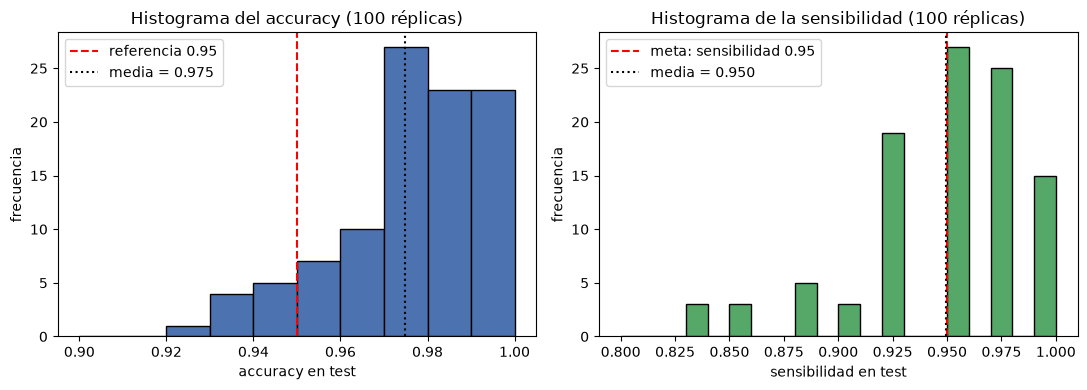

In [63]:
import os
import matplotlib.pyplot as plt

# Histogramas del accuracy y de la sensibilidad en las 100 réplicas.
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

ejes[0].hist(acc_mc, bins=np.arange(0.90, 1.005, 0.01), color="#4C72B0", edgecolor="black")
ejes[0].axvline(0.95, color="red", linestyle="--", linewidth=1.5, label="referencia 0.95")
ejes[0].axvline(media_acc, color="black", linestyle=":", linewidth=1.5, label=f"media = {media_acc:.3f}")
ejes[0].set_title("Histograma del accuracy (100 réplicas)")
ejes[0].set_xlabel("accuracy en test")
ejes[0].set_ylabel("frecuencia")
ejes[0].legend()

ejes[1].hist(sens_mc, bins=np.arange(0.80, 1.005, 0.01), color="#55A868", edgecolor="black")
ejes[1].axvline(0.95, color="red", linestyle="--", linewidth=1.5, label="meta: sensibilidad 0.95")
ejes[1].axvline(sens_mc.mean(), color="black", linestyle=":", linewidth=1.5, label=f"media = {sens_mc.mean():.3f}")
ejes[1].set_title("Histograma de la sensibilidad (100 réplicas)")
ejes[1].set_xlabel("sensibilidad en test")
ejes[1].set_ylabel("frecuencia")
ejes[1].legend()

plt.tight_layout()

# Se guarda también en PDF vectorial para el informe (carpeta informe/figuras).
os.makedirs("informe/figuras", exist_ok=True)
fig.savefig("informe/figuras/histogramas_monte_carlo.pdf", bbox_inches="tight")
plt.show()

### 5.3 Interpretación del OE3

**Resultados del Monte Carlo** (100 réplicas, reproducibles):

- **Accuracy de test:** media $0.9747$, desviación $0.0153$; intervalo de confianza del 95 %: $[0.9717,\ 0.9777]$. El promedio es muy estable: con 100 réplicas, el error estándar es apenas $0.0015$. El peor de los 100 experimentos acertó $0.9298$: incluso en mala suerte, la regla rinde bien.
- **Sensibilidad de test:** media $0.9495$, con réplicas entre $0.8333$ y $1.0$.
- **Probabilidad de cumplir la meta:** en $67$ de $100$ réplicas la sensibilidad de test fue $\geq 0.95$ → probabilidad estimada $0.67$.
- El **umbral también varía** entre particiones (media $0.529$, rango $[0.36, 0.70]$): no existe un umbral universal; se recalcula para cada conjunto de entrenamiento.

**Cómo se lee ese 0.67:** la bisección garantiza $S(t^*) \geq 0.95$ sobre las probabilidades de validación cruzada **del train**, pero el test es una muestra aleatoria de 114 tumores: qué malignos caigan en ella es cuestión de suerte, y cada maligno perdido mueve la sensibilidad en saltos de $\approx 1/42 \approx 0.024$. Por eso la garantía no es absoluta sino **probabilística**: en alrededor de 2 de cada 3 exámenes concretos la regla cumple la meta puntual, y en promedio queda prácticamente pegada a 0.95 ($0.9495$). Para la práctica médica, esto se traduce en: *el umbral por bisección es una buena regla para elevar la detección de malignos, pero conviene recalibrarlo con datos locales y mantener estudios complementarios para no depender de un solo sorteo de la vida real.*

## 6. Conclusiones

Las conclusiones responden **una por una** a los objetivos específicos, con las cifras del notebook como evidencia; al final se listan las limitaciones del estudio.

### Conclusión del OE1: el modelo base rinde bien, pero su umbral por defecto no protege lo suficiente

La regresión logística separó bien los tumores: accuracy de **0.9649** en test con el umbral por defecto 0.5, muy por encima del ≈ 0.63 de un clasificador trivial que siempre dijera "benigno". Sin embargo, la sensibilidad quedó en **0.9286** (39 de 42 malignos detectados): 3 tumores malignos dieron como benignos. El OE1 se cumplió como medición, y la medición misma reveló el problema central del proyecto: **un accuracy alto no es garantía de detección**, y el error más costoso (el falso negativo) quedaba sin control con el umbral estándar. Esa constatación es la que originó el OE2.

### Conclusión del OE2: la bisección encontró el umbral "justo" y quedó verificada contra la búsqueda exhaustiva

Planteada la meta como la raíz de $g(t) = S(t) - 0.95$, la bisección implementada a mano convergió en **20 iteraciones** — exactamente las que predice la teoría, pues $2^{20} > 10^{6}$ — al umbral **$t^* \approx 0.4819$**: el más alto que conserva sensibilidad $\geq 0.95$ sobre las probabilidades de validación cruzada del train. La verificación con malla fina de paso $10^{-6}$ coincidió con la bisección a $1.2 \times 10^{-7}$, confirmando que la implementación es correcta. En test, la regla "maligno si $P \geq 0.4819$" elevó la sensibilidad a **0.9524** (meta cumplida: 40 de 42) manteniendo la especificidad en 0.9861. El objetivo se cumplió: existe un umbral justificado, calculado **sin tocar el test**, que garantiza la sensibilidad exigida dentro del entrenamiento.

### Conclusión del OE3: el desempeño es estable

Con 100 repeticiones del experimento completo, el accuracy de test promedió **0.9747** con intervalo de confianza del 95 % de **[0.9717, 0.9777]**: el clasificador es consistentemente bueno (peor caso observado: 0.9298). La estimación clave, sin embargo, es la proporción de réplicas cuya sensibilidad de test cumplió la meta: **67 de 100, probabilidad estimada $0.67$**. La bisección garantiza 0.95 **dentro del entrenamiento**; en un examen nuevo, la sensibilidad promedio quedó en **0.9495** — prácticamente en la meta — pero partición a partición oscila entre 0.8333 y 1.0, porque cada maligno que se pierde mueve la sensibilidad en saltos de $\approx 1/42 \approx 0.024$. El OE3 cambió el tipo de respuesta del proyecto: de "cumple 0.95" a "**cumple 0.95 en torno a 2 de cada 3 exámenes concretos, y en promedio queda pegada a la meta**". Para uso real, eso se traduce en recalibrar el umbral con datos locales y no desmontar los estudios complementarios.

### Limitaciones

1. **Un solo dataset.** Todos los números provienen de 569 tumores de una única fuente (dataset de Wisconsin, mediciones de imágenes de aspiración con aguja fina). Sensibilidad, umbral y probabilidades no extrapolan automáticamente a otras poblaciones, equipos o protocolos.
2. **La sensibilidad es una función escalonada.** En test solo hay 42 malignos, así que $S(t)$ se mueve en saltos de $\approx 1/42 \approx 0.024$: la meta 0.95 solo puede observarse en valores discretos alcanzables (0.952, 0.976, ...) y pequeñas mejoras del modelo pueden resultar invisibles para la métrica.
3. **La validación cruzada usa parte de los datos.** Cada modelo de fold entrena con 4/5 del train, así que el umbral se decide con probabilidades de modelos algo más débiles que el modelo final (que entrena con todo el train); además, cada tumor del train es validado una sola vez. La garantía de la sección 4 es por tanto sobre "el experimento de entrenamiento", no sobre el modelo final exacto.
4. **El Monte Carlo es finito.** La probabilidad 0.67 es a su vez una estimación con 100 réplicas: su error estándar es $\sqrt{0.67 \cdot 0.33 / 100} \approx 0.047$, así que la "probabilidad de cumplir la meta" debería leerse con un intervalo aproximado de 0.67 ± 0.09, es decir, entre 0.58 y 0.76.